---
title: "Boundary-Value Problems — Level 2"
short_title: "03 Boundary-Value Problems"
numbering:
  heading_2: true
  equation: true
---

# Boundary-Value Problems

:::{seealso} Math for this topic
- [E-M2: Separation of variables and orthogonal functions](../math/02-separation-of-variables.ipynb)
- [M4: Linear ODEs, Fourier series and transforms](../../level2-book/math/04-linear-odes-fourier.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Mostly absent; start at Level 2 |
| **2** | **Griffiths, ch. 3** | **Separation of variables (Cartesian, spherical), method of images, uniqueness** |
| 3 | Jackson, ch. 2–3 | Green's functions, Legendre/Bessel expansions, mixed boundary conditions |

The new skill at this level: solving Laplace's equation with conductors as boundaries, using uniqueness to justify clever guesses

Math for this topic: E-M2, separation of variables and orthogonal functions (and mechanics M4 for Fourier series).
:::

Workbook example ladder: charge near a plane → charge near a grounded sphere → a point charge in a conducting sphere-and-hole geometry by Legendre series. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## Why Boundaries Change Everything

With conductors present, the charges on their surfaces arrange themselves in response to everything else, so the charge distribution is **unknown** and the Coulomb integral cannot be used directly. Instead, solve Poisson's equation (or Laplace's, in charge-free regions) subject to **boundary conditions**: the potential on each conductor, or its total charge.

Laplace's equation (E-M2) has no local extrema and obeys the averaging property. Those facts give the key theorem.

:::{prf:theorem} Uniqueness
:label: thm-uniqueness

1. In a region, the solution of Poisson's equation is **unique** once $V$ is specified on every boundary surface.
2. In a region surrounded by conductors, $\vec{E}$ is unique once the **total charge** on each conductor is given (and the charge density in the region).
:::

:::{prf:proof} Proof of the first statement
:class: dropdown
If $V_1$ and $V_2$ both solve the problem, their difference $V_3$ satisfies Laplace's equation inside and vanishes on every boundary. A harmonic function takes its extreme values on the boundary, so its maximum and minimum are both $0$. Hence $V_3 = 0$ everywhere.
:::

The practical meaning: **any** method that produces a function satisfying the equation and the boundary conditions has found **the** answer. Guessing is allowed. The method of images is organized guessing.

## The Method of Images

### A charge above a grounded plane

A point charge $q$ sits at height $d$ above an infinite grounded conducting plane ($z = 0$). Above the plane, we need $\nabla^2V = -\rho/\epsilon_0$ with $V = 0$ on the plane and at infinity.

Forget the conductor and place an **image charge** $-q$ at $z = -d$. The potential of the two charges,

$$
V(x, y, z) = \frac{q}{4\pi\epsilon_0}\left[\frac{1}{\sqrt{x^2 + y^2 + (z - d)^2}} - \frac{1}{\sqrt{x^2 + y^2 + (z + d)^2}}\right] ,
$$

satisfies the right equation above the plane (the image is outside the region) and vanishes on $z = 0$. By uniqueness, it **is** the potential above the plane. (Below the plane, inside the conductor, $V = 0$; the image is a calculational device, not a real charge.)

From it:

- The induced surface charge is $\sigma = -\epsilon_0\,\partial V/\partial z|_{z=0} = -\dfrac{qd}{2\pi(s^2 + d^2)^{3/2}}$, and it integrates to exactly $-q$.
- The force on $q$ is the attraction to its image: $F = \dfrac{1}{4\pi\epsilon_0}\dfrac{q^2}{(2d)^2}$, toward the plane.
- The energy needed to bring $q$ in from infinity is **half** the energy of the real two-charge system, because the field exists only above the plane.

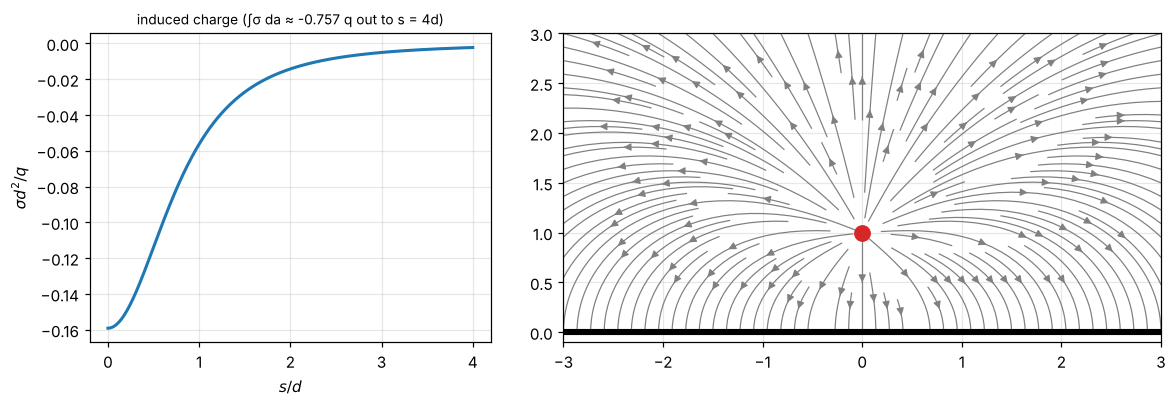

In [2]:
#| label: fig-image-plane
#| caption: Field lines of a charge above a grounded plane (right) and the induced surface charge (left), which integrates to −q. Field lines meet the conductor at right angles.
x = np.linspace(-3, 3, 300); z = np.linspace(0.001, 3, 160)
X, Z = np.meshgrid(x, z)
d = 1.0
def field(q, z0):
    r3 = (X**2 + (Z - z0)**2)**1.5
    return q * X / r3, q * (Z - z0) / r3
E1x, E1z = field(1, d); E2x, E2z = field(-1, -d)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
s = np.linspace(0, 4, 400)
sigma = -d / (2 * np.pi * (s**2 + d**2)**1.5)
axes[0].plot(s, sigma, lw=2)
Q_ind = np.trapezoid(sigma * 2 * np.pi * s, s)
axes[0].set_xlabel("$s/d$"); axes[0].set_ylabel(r"$\sigma d^2/q$"); axes[0].set_title(f"induced charge (∫σ da ≈ {Q_ind:.3f} q out to s = 4d)", fontsize=9)
axes[1].streamplot(X, Z, E1x + E2x, E1z + E2z, density=1.5, color="gray", linewidth=0.8)
axes[1].plot(0, d, "o", color="tab:red", ms=10)
axes[1].axhline(0, color="k", lw=4)
axes[1].set_aspect("equal"); axes[1].set_ylim(-0.1, 3)
plt.tight_layout(); plt.show()

### A charge outside a grounded sphere

A charge $q$ at distance $a$ from the center of a grounded conducting sphere of radius $R < a$. Try a single image $q'$ at distance $b$ from the center, on the same line. Requiring $V = 0$ at the two points of the sphere on that line fixes

$$
q' = -\frac{R}{a}\,q, \qquad b = \frac{R^2}{a} ,
$$

and one can check that $V = 0$ on the **whole** sphere with these values (a property of spheres, worked out below). The sphere attracts the charge with force

$$
F = \frac{1}{4\pi\epsilon_0}\frac{q^2Ra}{(a^2 - R^2)^2} .
$$

If the sphere is isolated and neutral instead of grounded, add a second image $+qR/a$ at the center: it keeps the surface an equipotential (now not at zero) and makes the total induced charge zero. That is uniqueness theorem 2 at work.

In [3]:
# Check that the image pair makes the whole sphere an equipotential at V = 0
th, R, a, q = sp.symbols("theta R a q", positive=True)
qp, bb = -R * q / a, R**2 / a
dist_q = sp.sqrt(R**2 + a**2 - 2 * a * R * sp.cos(th))
dist_img = sp.sqrt(R**2 + bb**2 - 2 * bb * R * sp.cos(th))
display(Math(r"4\pi\epsilon_0\,V\big|_{\text{sphere}} = " + sp.latex(sp.simplify(q / dist_q + qp / dist_img))))

<IPython.core.display.Math object>

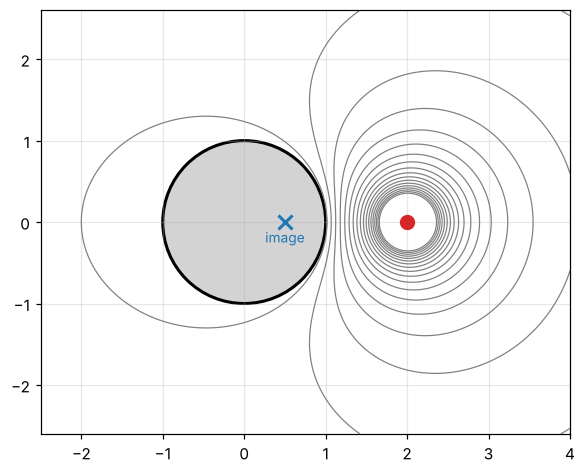

In [4]:
#| label: fig-image-sphere
#| caption: Equipotentials (gray) for a charge q at a = 2R outside a grounded sphere, computed from the charge plus its image (−q/2 at R/2). The sphere (black) is the V = 0 contour.
R_, a_ = 1.0, 2.0
x = np.linspace(-2.5, 4, 520); y = np.linspace(-2.6, 2.6, 420)
X, Y = np.meshgrid(x, y)
V = 1 / np.hypot(X - a_, Y) - (R_ / a_) / np.hypot(X - R_**2 / a_, Y)
V = np.where(np.hypot(X, Y) < R_, np.nan, V)
fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(X, Y, V, levels=np.r_[np.linspace(-0.2, -0.02, 4), np.linspace(0.05, 2.5, 18)], colors="gray", linewidths=0.8)
ax.add_patch(plt.Circle((0, 0), R_, color="lightgray", zorder=0)); ax.add_patch(plt.Circle((0, 0), R_, fill=False, color="k", lw=2))
ax.plot(a_, 0, "o", color="tab:red", ms=9); ax.plot(R_**2 / a_, 0, "x", color="tab:blue", ms=9, mew=2)
ax.text(R_**2 / a_, -0.25, "image", color="tab:blue", ha="center", fontsize=9)
ax.set_aspect("equal"); plt.show()

### Exercises

1. A charge $q$ sits at $(d, d, 0)$ near two grounded half-planes meeting at a right angle along the $z$-axis (the planes $x = 0$, $y > 0$ and $y = 0$, $x > 0$). Where are the images?
2. For the grounded sphere, show that the total induced charge is $-qR/a$, the image charge.
3. How much work does it take to pull $q$ from height $d$ above the grounded plane to infinity?

:::{dropdown} Hints
1. Reflect in each plane, then reflect the reflection.
2. Gauss's law: the flux through a surface just outside the sphere, from the induced charge alone, equals that of the image.
3. The force varies with height; integrate $F(z) = q^2/(4\pi\epsilon_0(2z)^2)$.
:::

:::{dropdown} Answers
1. $-q$ at $(-d, d, 0)$, $-q$ at $(d, -d, 0)$, and $+q$ at $(-d, -d, 0)$.
2. Outside the sphere the induced charge produces exactly the image's field, so by Gauss's law it has the same total, $-qR/a$.
3. $W = \displaystyle\int_d^\infty\frac{q^2}{16\pi\epsilon_0z^2}dz = \frac{q^2}{16\pi\epsilon_0d}$, half the energy of a real $\pm q$ pair at separation $2d$.
:::

## Separation of Variables

Images work only for special geometries. The general tool is separation of variables (E-M2), where the boundary conditions fix the coefficients of a series. The pipe with a parabolic lid in E-M2 is a Cartesian example. The most important spherical example:

::::{prf:example} A conducting sphere in a uniform field
:label: ex-sphere-uniform-field

An uncharged conducting sphere of radius $R$ is placed in a uniform field $\vec{E}_0 = E_0\hat{z}$. Find the potential outside and the induced surface charge.

:::{dropdown} Solution
Set the sphere's potential to $0$. Far away, $V\to -E_0z = -E_0r\cos\theta = -E_0rP_1(\cos\theta)$. Outside the sphere, the general solution is {eq}`eq-legendre-general` in E-M2. The condition at infinity allows only $A_1 = -E_0$ among the growing terms, and $V(R, \theta) = 0$ for all $\theta$ then requires every coefficient to vanish except $B_1 = E_0R^3$:

$$
V(r, \theta) = -E_0\left(r - \frac{R^3}{r^2}\right)\cos\theta .
$$

The second term is the potential of a **dipole** $p = 4\pi\epsilon_0R^3E_0$ at the center: the induced charges look like a dipole from outside. The surface charge is

$$
\sigma = -\epsilon_0\frac{\partial V}{\partial r}\bigg|_R = 3\epsilon_0E_0\cos\theta ,
$$

positive on the side the field points toward, negative on the other, and integrating to zero.
:::
::::

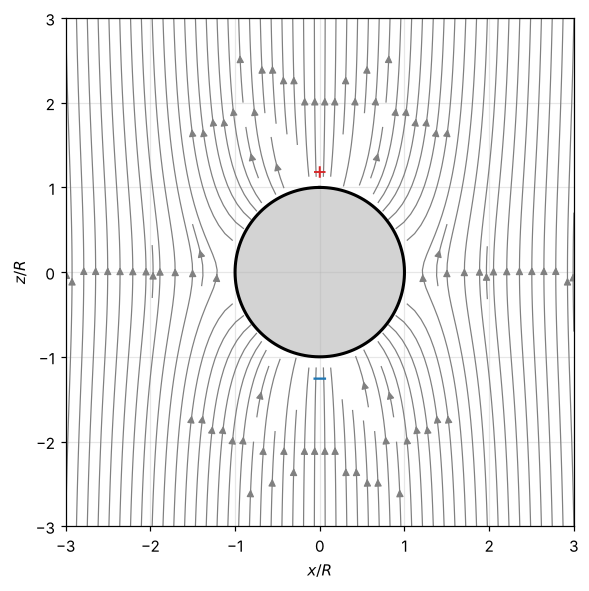

In [5]:
#| label: fig-sphere-uniform
#| caption: Field lines around a conducting sphere in a uniform field. Lines bend to meet the surface at right angles, crowding at the poles (where σ = ±3ε₀E₀) and avoiding the equator (where σ = 0).
R_ = 1.0
x = np.linspace(-3, 3, 300); z = np.linspace(-3, 3, 300)
X, Z = np.meshgrid(x, z)
r = np.hypot(X, Z)
# E = -grad V with V = -E0 (r - R^3/r^2) cos(theta), written in Cartesian components (E0 = 1)
Ex = 3 * R_**3 * X * Z / r**5
Ez = 1 + R_**3 * (3 * Z**2 - r**2) / r**5
inside = r < R_
Ex[inside] = np.nan; Ez[inside] = np.nan
fig, ax = plt.subplots(figsize=(6, 6))
ax.streamplot(X, Z, Ex, Ez, density=1.6, color="gray", linewidth=0.8)
th = np.linspace(0, 2 * np.pi, 300)
ax.fill(R_ * np.sin(th), R_ * np.cos(th), color="lightgray"); ax.plot(R_ * np.sin(th), R_ * np.cos(th), "k", lw=2)
ax.text(0, 1.1, "+", ha="center", fontsize=16, color="tab:red"); ax.text(0, -1.35, "−", ha="center", fontsize=18, color="tab:blue")
ax.set_aspect("equal"); ax.set_xlabel("$x/R$"); ax.set_ylabel("$z/R$"); plt.show()

## Numerical Relaxation for Awkward Shapes

When no symmetry helps, solve Laplace's equation on a grid. Fix $V$ on the conductors and the outer boundary, then repeatedly replace each free grid value with the average of its four neighbors (the averaging property). The method is slow but always works, and it is how real electrode designs are checked. **Over-relaxation** (stepping a bit past the average, by a factor $1 < \omega < 2$) speeds it up dramatically.

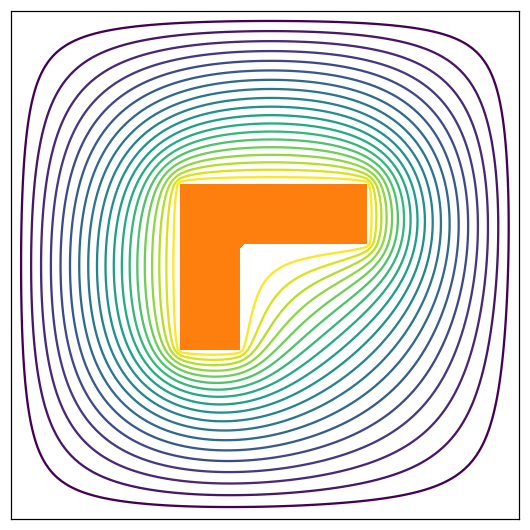

In [6]:
#| label: fig-relaxation
#| caption: An L-shaped conductor held at V = 1 inside a grounded square box, solved by successive over-relaxation. Equipotentials crowd at the L's outer (convex) corners, where the surface field and charge density are largest, and spread apart in its inner (concave) corner, where the field is weak.
N = 121
V = np.zeros((N, N))
fixed = np.zeros((N, N), bool)
fixed[0, :] = fixed[-1, :] = fixed[:, 0] = fixed[:, -1] = True
L = np.zeros((N, N), bool)
L[40:80, 40:55] = True; L[65:80, 40:85] = True            # an L-shaped electrode
V[L] = 1.0; fixed |= L
w = 1.9
for sweep in range(1500):
    for parity in (0, 1):                                  # red-black ordering, vectorized
        m = np.zeros((N, N), bool); m[1:-1, 1:-1] = True
        ii, jj = np.indices((N, N)); m &= ((ii + jj) % 2 == parity) & ~fixed
        avg = 0.25 * (np.roll(V, 1, 0) + np.roll(V, -1, 0) + np.roll(V, 1, 1) + np.roll(V, -1, 1))
        V[m] += w * (avg[m] - V[m])
fig, ax = plt.subplots(figsize=(6, 6))
cs = ax.contour(V, levels=np.linspace(0.05, 0.95, 19), cmap="viridis")
ax.contourf(np.where(L, 1, np.nan), colors=["tab:orange"])
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); plt.show()

### Exercises

1. Find the dipole moment induced on a conducting sphere of radius 5 cm in a field of $10^4$ V/m.
2. A grounded conducting sphere of radius $R$ is placed in a field that far away has potential $V\to -E_0r\cos\theta + kr^2P_2(\cos\theta)$. Write the potential outside.
3. Explain, using the uniqueness theorem, why the field inside an empty cavity in a conductor is zero no matter what charges are outside.

:::{dropdown} Hints
1. $p = 4\pi\epsilon_0R^3E_0$.
2. Each Legendre term is handled separately: for each $\ell$, add a $B_\ell r^{-(\ell+1)}$ term that cancels $A_\ell r^\ell$ at $r = R$.
3. $V = $ constant inside the cavity satisfies Laplace's equation and the boundary condition.
:::

:::{dropdown} Answers
1. $p = 4\pi(8.85\times10^{-12})(0.05)^3(10^4)\approx1.4\times10^{-10}$ C·m.
2. $V = -E_0\left(r - \dfrac{R^3}{r^2}\right)\cos\theta + k\left(r^2 - \dfrac{R^5}{r^3}\right)P_2(\cos\theta)$.
3. The cavity wall is an equipotential. A constant potential inside satisfies Laplace's equation and matches the wall, so by uniqueness it is the solution, and $\vec{E} = -\nabla V = \vec{0}$. This is how a Faraday cage works.
:::

## Summary

- With conductors, the charge distribution is unknown; solve Laplace's or Poisson's equation with boundary conditions instead.
- Uniqueness: the potential is fixed by its boundary values (or by each conductor's total charge), so a correct guess is the answer.
- Images replace conductors by fictitious charges outside the region: $-q$ mirrored in a plane; $-qR/a$ at $R^2/a$ for a sphere.
- Separation of variables handles boxes and spheres; a conducting sphere in a uniform field acquires a dipole $4\pi\epsilon_0R^3E_0$ and $\sigma = 3\epsilon_0E_0\cos\theta$.
- Relaxation on a grid solves any geometry.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.